# Spectrum extraction: optimal or aperture photometry

`get_spectrum` extracts a spectrum from the simulated cubes. This notebook
explains how: which object is extracted (the point source or its host), with
which **method** (optimal or aperture photometry), and within which
**aperture**.

## How it works

```python
sn.get_spectrum(method="aperture")                 # SN aperture photometry, within `aperture` around the SN
sn.get_spectrum(of_host=True, method="optimal")    # its host, PSF-weighted within the aperture
sn.change_properties(method="aperture", aperture="0.2-arcsec")   # stored: used by setup_to_snr, get_snr...
```

**What is extracted.** The point source if there is one, otherwise (e.g. a
`LazuliGalaxy`) or with `of_host=True`, the host galaxy.

**The method**, `method`:

| `method` | extraction |
|---|---|
| `"optimal"` | inverse-variance weighted fit of the PSF profile: the flux of the point source that best matches the cube |
| `"aperture"` | aperture photometry: plain summation of the signal and of the variance within the aperture |
| `"default"` | `"optimal"` for a point source; for the host, `"optimal"` if `aperture="core"`, `"aperture"` otherwise |

**The aperture**, `aperture` and `aperture__position`:

| `aperture` | radius |
|---|---|
| `"core"` | the point-source extraction radius (a few PSF sigma) |
| `"<n>-arcsec"`, e.g. `"1-arcsec"` | n arcsec [default: `"1-arcsec"`] |
| `"<n>-kpc"`, e.g. `"2-kpc"` | n kpc, at the redshift of the scene |

For a point source, the aperture is centered on it. For the host, it is
centered on `aperture__position`: the host position by default (`"host"`),
or any `(x, y)` position in spaxels.

`method`, `aperture` and `aperture__position` can be given to
`get_spectrum` for one call, or **stored** with `change_properties`; the
stored values are then used everywhere a spectrum is extracted:
`get_spectrum`, `get_band_snr`, `setup_to_snr`, `get_variance_contribution`...

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import slicersim

SKY = ["background", "thermal"]  # switched off in the images, to see the sources only

## 1. The scene

A SN Ia at z=0.9 on a spiral arm of NGC 0628, observed with a fixed
read-out mode. Positions are in spaxels of the narrow field (0.04 arcsec),
from the field center.

In [2]:
sn = slicersim.LazuliSupernova(redshift=0.9, host="ngc0628")
sn.change_properties(pointsource__position=[+10, 0], host__position=[+20, -10])
sn.change_detector(nmd=(64, 8, 0), nramps=2)
print(sn.get_readout_config(), f"exposure time: {sn.get_exposure_time() / 60:.0f} min")

sn.get_properties(["method", "aperture", "aperture__position"])   # the defaults

{'nmd': (64, 8, 0), 'nramps': 2} exposure time: 48 min


{'method': 'default', 'aperture': '1-arcsec', 'aperture__position': 'host'}

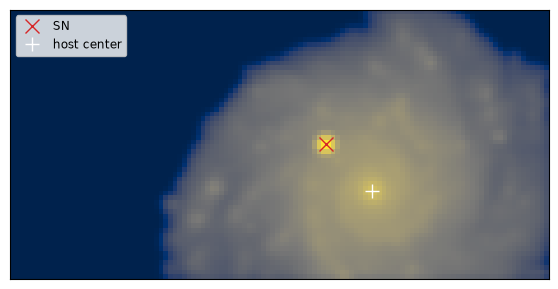

In [3]:
cube, _ = sn.get_cube(which="narrow", switch_off=SKY)
ny, nx = cube.shape[1:]

def to_pixel(position):
    # spaxel position (from the field center) to image pixel
    return (nx - 1) / 2 + position[0], (ny - 1) / 2 + position[1]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.imshow(cube.sum(axis=0), origin="lower", cmap="cividis", norm="asinh")
ax.plot(*to_pixel(sn.get_properties("pointsource__position", as_dict=False)), "x", color="C3", ms=10, label="SN")
ax.plot(*to_pixel(sn.get_properties("host__position", as_dict=False)), "+", color="w", ms=10, label="host center")
ax.legend(fontsize="small", loc="upper left")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 2. A point source: optimal or aperture photometry

By default, the supernova is extracted optimally (`method="default"`, i.e.
`"optimal"` for a point source). With `method="aperture"`, its light is
summed within `aperture`, centered on the supernova.

The aperture signal is the supernova light that actually falls within the
aperture: no aperture correction is applied. Such a correction would scale
the signal and the noise by the same factor, so it would not change the
signal-to-noise.

In [4]:
lbda, flux_opt, var_opt = sn.get_spectrum(method="optimal", incl_error=False)
restframe = (lbda > 4000 * 1.9) & (lbda < 6800 * 1.9)    # rest-frame 4000-6800 Å

def mean_snr(flux, variance):
    return np.mean(flux[restframe] / np.sqrt(variance[restframe]))

print(f"{'optimal':>12s}: flux fraction 1.000, snr {mean_snr(flux_opt, var_opt):5.2f}")
for aperture in ["0.05-arcsec", "0.1-arcsec", "0.2-arcsec", "0.5-arcsec", "1-arcsec"]:
    sn.change_properties(aperture=aperture)
    lbda, flux, var = sn.get_spectrum(method="aperture", incl_error=False)
    print(f"{aperture:>12s}: flux fraction {np.mean(flux[restframe] / flux_opt[restframe]):.3f}, "
          f"snr {mean_snr(flux, var):5.2f}")

     optimal: flux fraction 1.000, snr 13.36


 0.05-arcsec: flux fraction 0.641, snr 12.00


  0.1-arcsec: flux fraction 0.972, snr 11.81


  0.2-arcsec: flux fraction 1.000, snr  6.60


  0.5-arcsec: flux fraction 1.000, snr  2.83


    1-arcsec: flux fraction 1.000, snr  1.42


The optimal extraction gives the best signal-to-noise. A small aperture
loses part of the supernova light (PSF wings), and a large one adds the
noise of more spaxels (sky, host, detector) without adding signal.

Let us compare the spectra, with their errors:

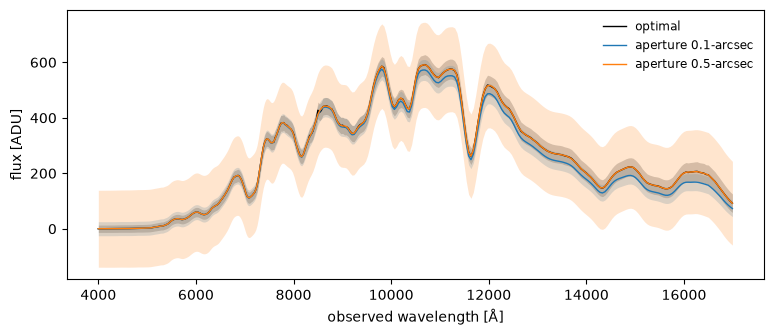

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(lbda, flux_opt, color="k", lw=1, label="optimal")
ax.fill_between(lbda, flux_opt - np.sqrt(var_opt), flux_opt + np.sqrt(var_opt), color="k", alpha=0.2, lw=0)

for aperture, color in zip(["0.1-arcsec", "0.5-arcsec"], ["C0", "C1"]):
    sn.change_properties(aperture=aperture)
    lbda, flux, var = sn.get_spectrum(method="aperture", incl_error=False)
    ax.plot(lbda, flux, color=color, lw=1, label=f"aperture {aperture}")
    ax.fill_between(lbda, flux - np.sqrt(var), flux + np.sqrt(var), color=color, alpha=0.2, lw=0)

ax.set(xlabel="observed wavelength [Å]", ylabel="flux [ADU]")
ax.legend(frameon=False, fontsize="small")
plt.show()

## 3. Storing the method: exposure time

`setup_to_snr` (and `get_band_snr`, `get_variance_contribution`...) uses the
**stored** method and aperture. Here is the read-out mode needed to reach a
signal-to-noise of 10 with each method:

In [6]:
for method, aperture in [("optimal", "1-arcsec"), ("aperture", "0.1-arcsec"), ("aperture", "0.2-arcsec")]:
    sn.change_properties(method=method, aperture=aperture)
    config, snr = sn.setup_to_snr(10)
    label = method if method == "optimal" else f"{method} {aperture}"
    print(f"{label:>20s}: {config}, snr={snr:.1f}, exposure time {sn.get_exposure_time() / 60:.0f} min")

             optimal: {'nmd': (35, 8, 0), 'nramps': 1}, snr=9.4, exposure time 13 min


 aperture 0.1-arcsec: {'nmd': (47, 8, 0), 'nramps': 1}, snr=10.2, exposure time 18 min


 aperture 0.2-arcsec: {'nmd': (64, 8, 0), 'nramps': 2}, snr=10.0, exposure time 48 min


Set `method="default"` to come back to the default behaviour:

In [7]:
sn.change_properties(method="default", aperture="1-arcsec")
sn.change_detector(nmd=(64, 8, 0), nramps=2)
sn.get_properties(["method", "aperture"])

{'method': 'default', 'aperture': '1-arcsec'}

## 4. The host of a point source: `of_host=True`

With `of_host=True`, the host is extracted instead of the point source,
within the aperture centered on `aperture__position` (the host position by
default). The supernova is then a source of noise, not of signal.

In [8]:
lbda, flux_host, var_host = sn.get_spectrum(of_host=True, incl_error=False)   # 1 arcsec around the host center
print("host, 1 arcsec around its center: snr", round(mean_snr(flux_host, var_host), 2))

host, 1 arcsec around its center: snr 4.87


Moving the aperture onto the supernova gives the host light *under* the
supernova, i.e. the host contamination of the supernova spectrum within the
same aperture:

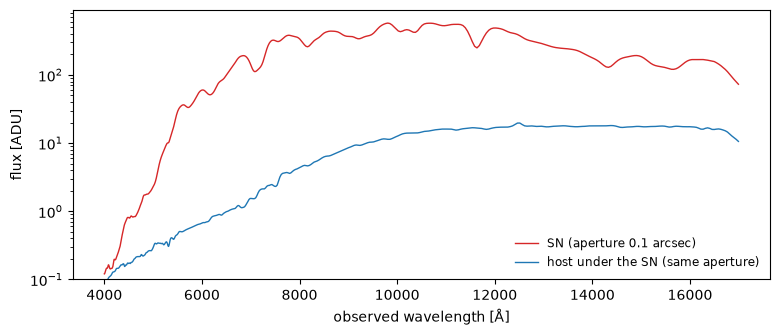

host / SN within 0.1 arcsec: 2.8%


In [9]:
sn_position = sn.get_properties("pointsource__position", as_dict=False)
sn.change_properties(aperture="0.1-arcsec", aperture__position=sn_position)

lbda, flux_under, var_under = sn.get_spectrum(of_host=True, incl_error=False)   # host under the SN
lbda, flux_sn, var_sn = sn.get_spectrum(method="aperture", incl_error=False)    # SN, same aperture

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(lbda, flux_sn, color="C3", lw=1, label="SN (aperture 0.1 arcsec)")
ax.plot(lbda, flux_under, color="C0", lw=1, label="host under the SN (same aperture)")
ax.set(xlabel="observed wavelength [Å]", ylabel="flux [ADU]", yscale="log", ylim=(0.1, None))
ax.legend(frameon=False, fontsize="small")
plt.show()

print(f"host / SN within 0.1 arcsec: {np.mean(flux_under[restframe]) / np.mean(flux_sn[restframe]):.1%}")

`method` also applies to the host: `method="optimal"` fits the PSF within
the aperture (as `aperture="core"` does), i.e. it measures the
point-source-like part of the host light at that position.

In [10]:
for method in ["aperture", "optimal"]:
    lbda, flux, var = sn.get_spectrum(of_host=True, method=method, incl_error=False)
    print(f"host under the SN, {method:>8s}: mean flux {np.mean(flux[restframe]):6.1f} ADU, "
          f"snr {mean_snr(flux, var):.2f}")

sn.change_properties(aperture="1-arcsec", aperture__position="host")   # back to the defaults

host under the SN, aperture: mean flux   11.5 ADU, snr 0.33


host under the SN,  optimal: mean flux    8.1 ADU, snr 0.25


For an extended source such as the host, aperture photometry is the better
choice: the PSF weights only use the light of the PSF core, so the optimal
extraction has a lower signal-to-noise.

## 5. A galaxy alone

Without point source, e.g. a `LazuliGalaxy`, the galaxy is always the
extracted object, and the same options apply. See the
[galaxy tutorial](beginner_galaxy.ipynb).

```python
galaxy = slicersim.LazuliGalaxy(redshift=0.5, model="ngc0628", aperture="2-kpc")
lbda, flux, variance = galaxy.get_spectrum()                    # aperture photometry within 2 kpc
lbda, flux, variance = galaxy.get_spectrum(method="optimal")    # PSF-weighted within 2 kpc
```

```{note}
The optimal point-source signal is the input spectrum, smoothed by the line
spread function (LSF) and then converted to photons, while the aperture
signals are measured on the cubes, converted to photons and then smoothed by
the LSF. Where the throughput changes quickly with wavelength, both can
differ by up to a few percent.
```